# 00_02 Expectation, Variance, Moments and the MGF

**Learning objectives**
- Compute the **expected value** (mean), **variance**, **moments**, **skewness** and **kurtosis** of discrete and continuous random variables.
- Use **linearity of expectation** and the variance rules.
- Use the **moment generating function (MGF)** to produce moments.
- Solve a raffle and an insurance problem by hand, in code and by simulation.

**Prerequisites:** [00_01 Random variables](00_01_random_variables.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- A discrete random variable has a PMF $p(x)$; a continuous one has a PDF $f(x)$; the CDF is $F(x)=P(X\le x)$.
- Probabilities add to 1: $\sum p(x)=1$ or $\int f=1$.
- Sums and integrals: $\sum_x$ for discrete, $\int dx$ for continuous.

## 3. Intuition and story

The **expected value** is the long-run average: if you repeat the experiment many times, the average result approaches $E[X]$ (the Law of Large Numbers). It is the "center of mass" of the distribution. The **variance** measures how spread out the results are around that average (the typical squared deviation), and the **standard deviation** is its square root, in the original units.

Higher **moments** capture shape: **skewness** (is the distribution lopsided?) and **kurtosis** (how heavy are the tails?). The **MGF** packs all moments into one function, which makes proofs about sums of independent variables easy.

## 4. Formal definition

$$E[X]=\sum_xx\,p(x)\quad\text{or}\quad\int xf(x)dx,\qquad E[g(X)]=\sum_xg(x)p(x)\ \text{ or }\ \int g(x)f(x)dx\ \text{(the "law of the unconscious statistician")}.$$

- **Variance:** $\mathrm{Var}(X)=E[(X-\mu)^2]=E[X^2]-\mu^2$; **SD** $\sigma=\sqrt{\mathrm{Var}}$.
- **$k$-th moment:** $E[X^k]$; **central moment:** $E[(X-\mu)^k]$.
- **Skewness:** $E\big[\big(\tfrac{X-\mu}\sigma\big)^3\big]$; **kurtosis:** $E\big[\big(\tfrac{X-\mu}\sigma\big)^4\big]$ (excess kurtosis = kurtosis $-3$; the Normal has 0).
- **MGF:** $M_X(t)=E[e^{tX}]$ for $t$ near 0.

## 5. Derivations

**Linearity.** $E[aX+b]=\sum(ax+b)p(x)=a\sum xp(x)+b\sum p(x)=aE[X]+b$. Also $E[X+Y]=E[X]+E[Y]$ always (even for dependent variables).

**Variance shortcut.** $E[(X-\mu)^2]=E[X^2-2\mu X+\mu^2]=E[X^2]-2\mu^2+\mu^2=E[X^2]-\mu^2$.

**Variance rules.** $\mathrm{Var}(aX+b)=a^2\mathrm{Var}(X)$ (shifting does nothing; scaling multiplies by $a^2$). For **independent** $X,Y$: $\mathrm{Var}(X+Y)=\mathrm{Var}(X)+\mathrm{Var}(Y)$.

**The mean minimizes squared error.** $E[(X-c)^2]=\mathrm{Var}(X)+(\mu-c)^2$, smallest at $c=\mu$.

**MGF gives moments.** Expanding $e^{tX}=1+tX+\frac{t^2X^2}{2!}+\dots$ gives $M(t)=1+tE[X]+\frac{t^2}{2}E[X^2]+\dots$, so $E[X^k]=M^{(k)}(0)$. For independent $X,Y$: $M_{X+Y}(t)=M_X(t)M_Y(t)$.

**Example: Bernoulli($p$).** $E[X]=p$, $E[X^2]=p$, $\mathrm{Var}=p-p^2=p(1-p)$, $M(t)=1-p+pe^t$, $M'(0)=p$. **Normal($\mu,\sigma^2$):** $M(t)=e^{\mu t+\sigma^2t^2/2}$, so $M'(0)=\mu$ and $M''(0)=\mu^2+\sigma^2$.

**In plain words.** The mean is a weighted average, variance is the average squared distance from it, and the MGF is a "generating machine": differentiate it at 0 to get any moment.

## 6. Properties and relationships

- **Linearity needs no independence;** the variance addition rule does.
- **Law of Large Numbers:** the sample mean converges to $E[X]$ (if it exists).
- **Heavy tails:** some distributions have no mean (Cauchy) or no variance (Pareto with $\alpha\le2$); see Module 02.
- **Standardizing:** $Z=(X-\mu)/\sigma$ has mean 0 and variance 1.
- **Skewness sign:** positive means a long right tail (mean > median).

## 7. 2D visuals

### 7.1 Mean as balance point and variance as spread
Two PMFs with the same mean 5 but different spread.

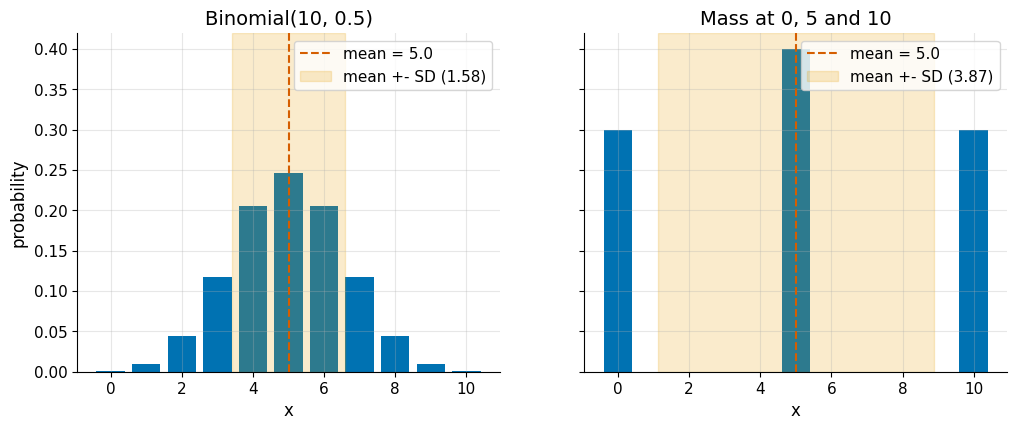

In [2]:
values = np.arange(0, 11)
narrow = stats.binom(10, 0.5).pmf(values)                     # mean 5, variance 2.5
wide = np.where(values % 5 == 0, np.array([0.3, 0, 0, 0, 0, 0.4, 0, 0, 0, 0, 0.3]), 0.0)   # mass at 0, 5, 10: mean 5
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, pmf, title in [(axes[0], narrow, "Binomial(10, 0.5)"), (axes[1], wide, "Mass at 0, 5 and 10")]:
    mean = (values * pmf).sum()
    sd = np.sqrt(((values - mean) ** 2 * pmf).sum())
    ax.bar(values, pmf, color=MAIN)
    ax.axvline(mean, color=HIGHLIGHT, linestyle="--", label=f"mean = {mean:.1f}")
    ax.axvspan(mean - sd, mean + sd, color=SIM, alpha=0.2, label=f"mean +- SD ({sd:.2f})")
    ax.set_title(title)
    ax.set_xlabel("x")
    ax.legend()
axes[0].set_ylabel("probability")
plt.show()

### 7.2 The mean minimizes the average squared error
The expected squared error E[(X - c)^2] is a parabola in c with its minimum at the mean (the minimum value is the variance).

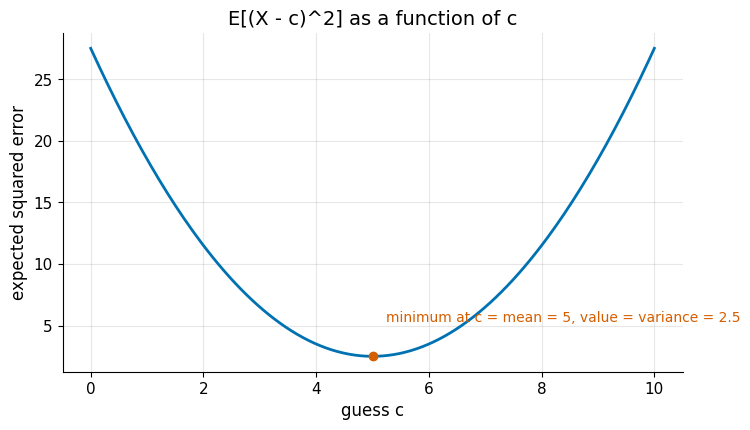

In [3]:
c_axis = np.linspace(0, 10, 200)
errors = [((values - c) ** 2 * narrow).sum() for c in c_axis]
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.plot(c_axis, errors, color=MAIN, linewidth=2)
ax.plot([5], [2.5], "o", color=HIGHLIGHT)
ax.annotate("minimum at c = mean = 5, value = variance = 2.5", (5, 2.5), textcoords="offset points", xytext=(10, 25), color=HIGHLIGHT)
ax.set_title("E[(X - c)^2] as a function of c")
ax.set_xlabel("guess c")
ax.set_ylabel("expected squared error")
plt.show()

### 7.3 Skewness and kurtosis
Three shapes with the same mean 0 and variance 1: symmetric Normal, right-skewed Exponential (shifted), and heavy-tailed Laplace.

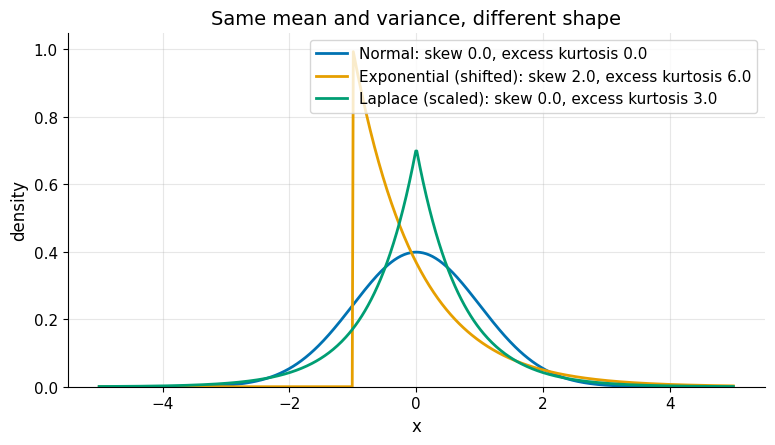

In [4]:
x_axis = np.linspace(-5, 5, 600)
shapes = [("Normal", stats.norm(0, 1)), ("Exponential (shifted)", stats.expon(loc=-1, scale=1)), ("Laplace (scaled)", stats.laplace(0, 1 / np.sqrt(2)))]
fig, ax = plt.subplots(figsize=(9, 4.6))
for (name, dist), color in zip(shapes, COLORS):
    skew, excess = dist.stats(moments="sk")
    ax.plot(x_axis, dist.pdf(x_axis), color=color, linewidth=2, label=f"{name}: skew {float(skew):.1f}, excess kurtosis {float(excess):.1f}")
ax.set_ylim(0, 1.05)
ax.set_title("Same mean and variance, different shape")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: the Normal MGF over (t, sigma)
M(t) = exp(mu t + sigma^2 t^2 / 2) with mu = 0 grows quickly with |t| and sigma.

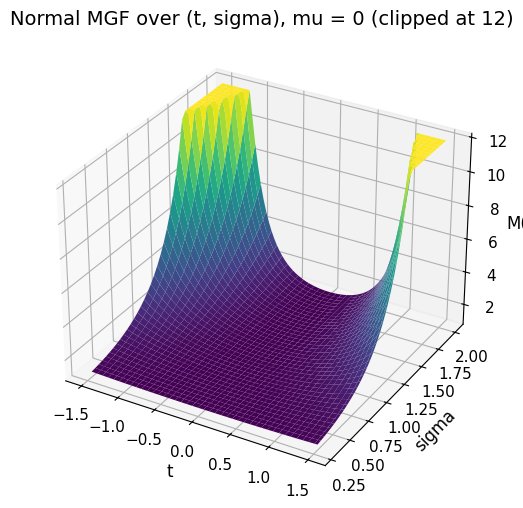

In [5]:
t_values = np.linspace(-1.5, 1.5, 80)
sigma_values = np.linspace(0.3, 2, 40)
T, S = np.meshgrid(t_values, sigma_values)
M = np.exp(S**2 * T**2 / 2)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(T, S, np.minimum(M, 12), cmap="viridis", edgecolor="none")
ax.set_title("Normal MGF over (t, sigma), mu = 0 (clipped at 12)")
ax.set_xlabel("t")
ax.set_ylabel("sigma")
ax.set_zlabel("M(t)")
ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: expected squared error over (c, sigma)

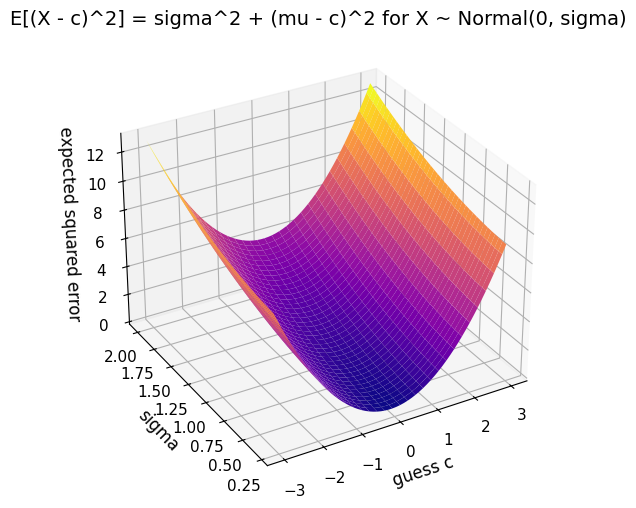

In [6]:
c_values = np.linspace(-3, 3, 60)
C, S2 = np.meshgrid(c_values, sigma_values)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(C, S2, S2**2 + C**2, cmap="plasma", edgecolor="none")
ax.set_title("E[(X - c)^2] = sigma^2 + (mu - c)^2 for X ~ Normal(0, sigma)")
ax.set_xlabel("guess c")
ax.set_ylabel("sigma")
ax.set_zlabel("expected squared error")
ax.view_init(elev=30, azim=-120)
plt.show()

### 8.3 Interactive Plotly version

In [7]:
fig = go.Figure(go.Surface(x=t_values, y=sigma_values, z=np.minimum(M, 12), colorscale="Viridis"))
fig.update_layout(title="Normal MGF over (t, sigma), mu = 0 (clipped at 12)", width=750, height=550,
                  scene=dict(xaxis_title="t", yaxis_title="sigma", zaxis_title="M(t)"))
fig.show()

## 9. Simulation vs theory

### 9.1 Moments by simulation
For Exponential(1): mean 1, variance 1, skewness 2, excess kurtosis 6.

mean 1.000 (1), variance 1.000 (1), skewness 2.00 (2), excess kurtosis 6.0 (6)


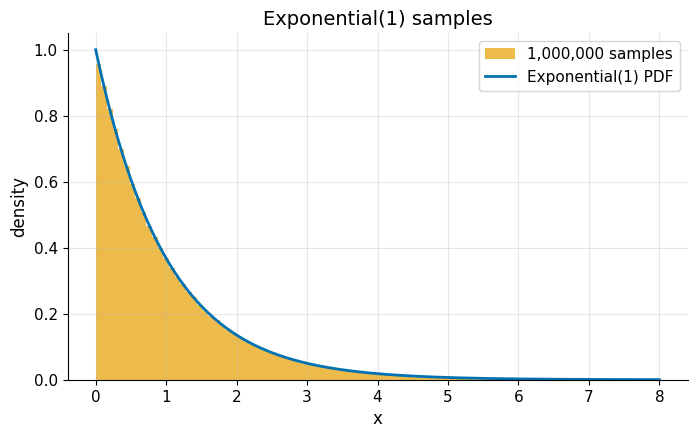

In [8]:
samples = rng.exponential(1, size=1_000_000)
print(f"mean {samples.mean():.3f} (1), variance {samples.var():.3f} (1), skewness {stats.skew(samples):.2f} (2), excess kurtosis {stats.kurtosis(samples):.1f} (6)")
fig, ax = plt.subplots()
ax.hist(samples, bins=100, range=(0, 8), density=True, color=SIM, alpha=0.7, label="1,000,000 samples")
grid = np.linspace(0, 8, 300)
ax.plot(grid, stats.expon.pdf(grid), color=MAIN, linewidth=2, label="Exponential(1) PDF")
ax.set_title("Exponential(1) samples")
ax.set_xlabel("x")
ax.set_ylabel("density")
ax.legend()
plt.show()

### 9.2 Law of Large Numbers: the running mean

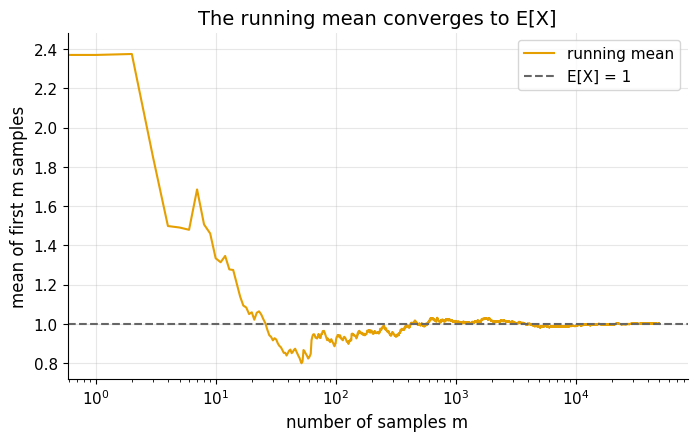

In [9]:
running_mean = np.cumsum(samples[:50_000]) / np.arange(1, 50_001)
fig, ax = plt.subplots()
ax.plot(running_mean, color=SIM, label="running mean")
ax.axhline(1, color=NEUTRAL, linestyle="--", label="E[X] = 1")
ax.set_xscale("log")
ax.set_title("The running mean converges to E[X]")
ax.set_xlabel("number of samples m")
ax.set_ylabel("mean of first m samples")
ax.legend()
plt.show()

## 10. `scipy.stats` cheat sheet

In [10]:
d = stats.gamma(a=3, scale=2)
print("mean, var, std      :", d.mean(), d.var(), round(d.std(), 4))
print("moment(2) = E[X^2]  :", d.moment(2), "(= var + mean^2 =", d.var() + d.mean() ** 2, ")")
print("stats mvsk          :", np.round(d.stats(moments="mvsk"), 4))
print("expect(lambda x: x**3):", round(d.expect(lambda x: x**3), 3), "(third raw moment by numerical integration)")
data = rng.gamma(3, 2, size=100_000)
print("sample skew, kurtosis:", round(stats.skew(data), 3), round(stats.kurtosis(data), 3))

mean, var, std      : 6.0 12.0 3.4641
moment(2) = E[X^2]  : 48.0 (= var + mean^2 = 48.0 )
stats mvsk          : [ 6.     12.      1.1547  2.    ]
expect(lambda x: x**3): 480.0 (third raw moment by numerical integration)
sample skew, kurtosis: 1.152 1.97


## 11. Real-world worked example: a raffle

**Scenario (illustrative numbers).** A charity sells **1,000 tickets at 5 each**. Prizes: **1 prize of 1,000**, **5 prizes of 100**, **20 prizes of 20**; all other tickets win nothing. You buy one ticket; let $X$ be your prize.

**Questions**
1. What is the **expected prize** and your **expected profit** per ticket?
2. What are the **variance and standard deviation** of the prize?
3. You buy **10 tickets**. What is your expected profit, and the SD of the total prize (treat tickets as independent)?

### 11.1 By hand
Distribution of $X$: $P(X=1000)=\frac1{1000}$, $P(X=100)=\frac5{1000}$, $P(X=20)=\frac{20}{1000}$, $P(X=0)=\frac{974}{1000}$.

**Q1.** $E[X]=1000\cdot0.001+100\cdot0.005+20\cdot0.02+0\cdot0.974=1+0.5+0.4=1.9$. Profit $=1.9-5=-3.10$ per ticket.

**Q2.** $E[X^2]=1000^2\cdot0.001+100^2\cdot0.005+20^2\cdot0.02=1000+50+8=1058$. $\mathrm{Var}=1058-1.9^2=1058-3.61=1054.39$, SD $=32.47$.

**Q3.** Linearity: expected total prize $=10\times1.9=19$, expected profit $=19-50=-31$. Independent tickets: $\mathrm{Var}=10\times1054.39=10543.9$, SD $=102.7$.

In [11]:
prizes = np.array([1000, 100, 20, 0])
probabilities = np.array([1, 5, 20, 974]) / 1000
ticket_price = 5

expected_prize_hand = 0.0
second_moment_hand = 0.0
for prize, probability in zip(prizes, probabilities):
    expected_prize_hand += prize * probability
    second_moment_hand += prize**2 * probability
variance_hand = second_moment_hand - expected_prize_hand**2
print(f"E[X] = {expected_prize_hand:.2f}, profit = {expected_prize_hand - ticket_price:.2f}, Var = {variance_hand:.2f}, SD = {variance_hand ** 0.5:.2f}")
print(f"10 tickets: expected profit = {10 * expected_prize_hand - 10 * ticket_price:.1f}, SD of total prize = {(10 * variance_hand) ** 0.5:.1f}")

E[X] = 1.90, profit = -3.10, Var = 1054.39, SD = 32.47
10 tickets: expected profit = -31.0, SD of total prize = 102.7


### 11.2 In code with `scipy`, and the asserts
`stats.rv_discrete` builds a distribution from values and probabilities.

In [12]:
prize_dist = stats.rv_discrete(values=(prizes, probabilities))
assert np.isclose(expected_prize_hand, prize_dist.mean())
assert np.isclose(variance_hand, prize_dist.var())
assert np.isclose(10 * expected_prize_hand, 10 * prize_dist.mean())
print(f"mean {prize_dist.mean():.2f}, var {prize_dist.var():.2f}, skewness {float(prize_dist.stats(moments='s')):.1f} (extremely right skewed)")

mean 1.90, var 1054.39, skewness 29.2 (extremely right skewed)


### 11.3 Verify by simulation
We also simulate the actual raffle (10 distinct tickets drawn without replacement) and compare.

In [13]:
tickets = np.repeat(prizes, [1, 5, 20, 974])                         # the 1,000 tickets and their prizes
totals = np.array([rng.choice(tickets, size=10, replace=False).sum() for _ in range(100_000)])
single = rng.choice(tickets, size=500_000)
print(f"one ticket:  mean {single.mean():.3f} (theory {expected_prize_hand:.2f}), SD {single.std():.2f} (theory {variance_hand ** 0.5:.2f})")
print(f"ten tickets: expected profit {totals.mean() - 50:.1f} (theory -31.0), SD {totals.std():.1f} (independent approximation 102.7)")
print(f"P(break even or better with 10 tickets) = {np.mean(totals >= 50):.4f}")
assert abs(single.mean() - expected_prize_hand) < 0.15

one ticket:  mean 1.889 (theory 1.90), SD 32.15 (theory 32.47)
ten tickets: expected profit -30.9 (theory -31.0), SD 103.0 (independent approximation 102.7)
P(break even or better with 10 tickets) = 0.0590


### 11.4 Plots

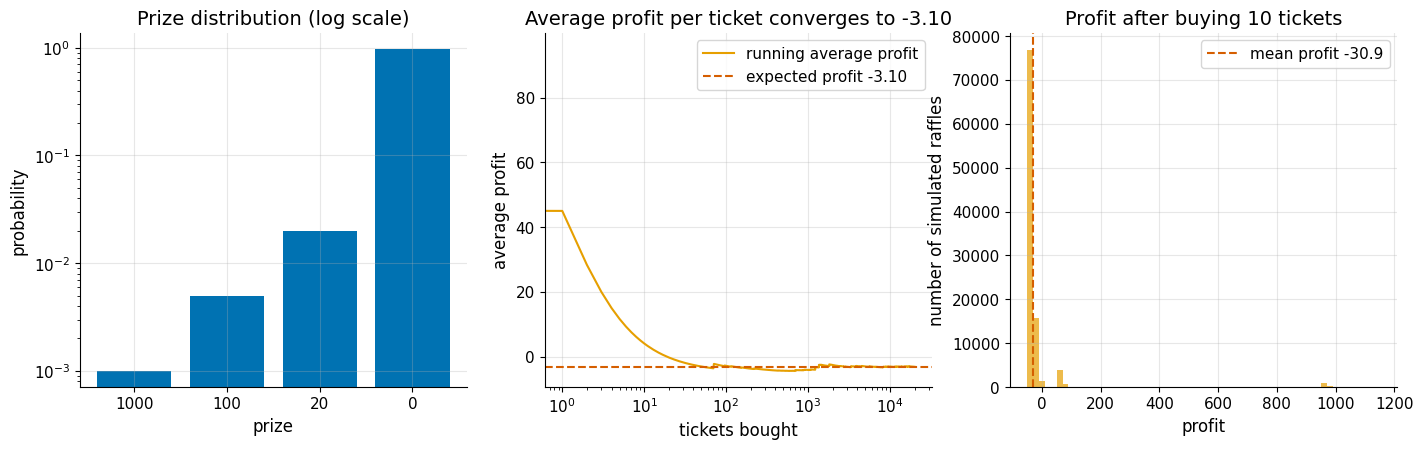

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
axes[0].bar([str(p) for p in prizes], probabilities, color=MAIN)
axes[0].set_yscale("log")
axes[0].set_title("Prize distribution (log scale)")
axes[0].set_xlabel("prize")
axes[0].set_ylabel("probability")

axes[1].plot(np.cumsum(single[:20_000]) / np.arange(1, 20_001) - ticket_price, color=SIM, label="running average profit")
axes[1].axhline(expected_prize_hand - ticket_price, color=HIGHLIGHT, linestyle="--", label="expected profit -3.10")
axes[1].set_xscale("log")
axes[1].set_title("Average profit per ticket converges to -3.10")
axes[1].set_xlabel("tickets bought")
axes[1].set_ylabel("average profit")
axes[1].legend()

axes[2].hist(totals - 50, bins=60, color=SIM, alpha=0.7)
axes[2].axvline(totals.mean() - 50, color=HIGHLIGHT, linestyle="--", label=f"mean profit {totals.mean() - 50:.1f}")
axes[2].set_title("Profit after buying 10 tickets")
axes[2].set_xlabel("profit")
axes[2].set_ylabel("number of simulated raffles")
axes[2].legend()
plt.show()

### 11.5 Interpretation and decision
- Each ticket is worth **1.90** in expected prize but costs **5**: you lose **3.10 on average** (the charity keeps 3,100 in total).
- The **SD (32) is much larger than the mean (1.9)**: most tickets win nothing (97.4 %), and a few win a lot. The average only shows up over many tickets, as the running-average plot shows.
- **Decision:** buy tickets only as a donation. Never rely on the expected value for a single ticket: the typical outcome (0) differs from the mean (1.9).

### 11.6 Extra example: an insurance policy
A policy costs **600 per year**. With probability **0.04** the insurer pays a claim of **10,000**, otherwise 0. For the insurer, profit per policy is $Y=600-C$.

In [15]:
claim_prob, claim_size, premium = 0.04, 10_000, 600
expected_claim_hand = claim_prob * claim_size
expected_profit_hand = premium - expected_claim_hand
variance_hand_ins = claim_size**2 * claim_prob * (1 - claim_prob)            # Bernoulli variance times the squared claim size
sd_hand = variance_hand_ins ** 0.5
n_policies = 1000
total_mean, total_sd = n_policies * expected_profit_hand, (n_policies * variance_hand_ins) ** 0.5
p_loss_hand = stats.norm(total_mean, total_sd).cdf(0)                         # CLT approximation

claims = rng.binomial(1, claim_prob, size=(20_000, n_policies)) * claim_size
total_profits = n_policies * premium - claims.sum(axis=1)
print(f"per policy: expected profit {expected_profit_hand:.0f}, SD {sd_hand:.0f}")
print(f"1,000 policies: expected profit {total_mean:,.0f}, SD {total_sd:,.0f}; P(loss) approx {p_loss_hand:.4f}, simulated {np.mean(total_profits < 0):.4f}")
assert np.isclose(total_profits.mean(), total_mean, rtol=0.02)
assert abs(p_loss_hand - np.mean(total_profits < 0)) < 0.01

per policy: expected profit 200, SD 1960
1,000 policies: expected profit 200,000, SD 61,968; P(loss) approx 0.0006, simulated 0.0010


**Interpretation.** Each policy earns **200 on average** but with a large SD (1,960): one policy can lose 9,400. Over **1,000 policies** the total profit has mean 200,000 and SD 61,968, so the chance of a loss is only about **0.1 %**: that is the **Law of Large Numbers** at work, and the reason insurance works.

## 12. Where it is used

### Statistics
- Estimators (the sample mean estimates $E[X]$), bias and variance of estimators, method of moments, MGFs in proofs of the Central Limit Theorem.

### Data science
- Expected revenue, expected loss and **risk** (standard deviation); KPI averages and their uncertainty; skewness and kurtosis to describe a feature.

### ML and AI
- **Loss = expected error** (risk minimization); the mean minimizes squared error, the median absolute error; batch normalization uses mean and variance; variance of gradient estimates matters in SGD.

## 13. Common pitfalls and misconceptions

- **The expected value need not be a possible outcome** (1.9 above) and may not be typical.
- **The mean may not exist** (Cauchy) or the variance may be infinite (heavy-tailed data).
- **Variance adds only for independent variables;** otherwise add the covariance terms (00_03).
- **Var(aX) = a^2 Var(X)**, not a Var(X); SD scales by |a|.
- **Sample variance uses n - 1** (`np.var(..., ddof=1)`), unlike the population formula.
- **E[g(X)] is not g(E[X])** in general (E[X^2] = 1058 but (E[X])^2 = 3.61).

## 14. Exercises

1. A fair die is rolled. Find $E[X]$, $\mathrm{Var}(X)$, and $E[X^2]$.
2. If $E[X]=10$ and $\mathrm{Var}(X)=4$, find $E[3X-2]$ and $\mathrm{Var}(3X-2)$.
3. A game pays 10 with probability 0.2 and costs 3 to play. Is it fair? Find the expected profit.
4. Show that $\mathrm{Var}(X)=E[X^2]-(E[X])^2$ for an Exponential($\lambda$) using $E[X]=1/\lambda$ and $E[X^2]=2/\lambda^2$.
5. (Harder) Use the MGF $M(t)=\frac{\lambda}{\lambda-t}$ of the Exponential to get its mean and variance.

Solutions are at the end.

## 15. Summary table

| Quantity | Formula | `scipy` |
|---|---|---|
| Mean | E[X] | `.mean()` |
| Variance | E[X^2] - E[X]^2 | `.var()` |
| k-th moment | E[X^k] | `.moment(k)` |
| Skewness / kurtosis | standardized 3rd / 4th moments | `.stats(moments="sk")` |
| E[g(X)] | sum or integral of g p | `.expect(g)` |
| MGF | E[exp(tX)] | (closed form) |

## Solutions

In [16]:
faces = np.arange(1, 7)
print("1: E[X] =", faces.mean(), " E[X^2] =", (faces**2).mean(), " Var =", round((faces**2).mean() - faces.mean() ** 2, 4))
print("2: E[3X - 2] =", 3 * 10 - 2, " Var(3X - 2) =", 9 * 4)
print("3: expected profit =", 10 * 0.2 - 3, "(not fair: the player loses 1 on average)")
print("4: 2/lambda^2 - 1/lambda^2 = 1/lambda^2; check lambda = 2:", stats.expon(scale=0.5).var(), 1 / 4)
print("5: M'(0) = 1/lambda, M''(0) = 2/lambda^2 (differentiating lambda/(lambda - t) once and twice at t = 0)")

1: E[X] = 3.5  E[X^2] = 15.166666666666666  Var = 2.9167
2: E[3X - 2] = 28  Var(3X - 2) = 36
3: expected profit = -1.0 (not fair: the player loses 1 on average)
4: 2/lambda^2 - 1/lambda^2 = 1/lambda^2; check lambda = 2: 0.25 0.25
5: M'(0) = 1/lambda, M''(0) = 2/lambda^2 (differentiating lambda/(lambda - t) once and twice at t = 0)


**1.** $E[X]=3.5$, $E[X^2]=91/6=15.17$, $\mathrm{Var}=15.17-12.25=2.92$.

**2.** $E[3X-2]=28$; $\mathrm{Var}(3X-2)=9\times4=36$.

**3.** Expected winnings $=2$, profit $=2-3=-1$: the game is **not fair** (the player loses 1 on average).

**4.** $\mathrm{Var}=\frac2{\lambda^2}-\frac1{\lambda^2}=\frac1{\lambda^2}$.

**5.** $M'(t)=\frac\lambda{(\lambda-t)^2}\Rightarrow M'(0)=\frac1\lambda$; $M''(t)=\frac{2\lambda}{(\lambda-t)^3}\Rightarrow M''(0)=\frac2{\lambda^2}$; variance $=\frac2{\lambda^2}-\frac1{\lambda^2}=\frac1{\lambda^2}$.